# 01 · Carga y comprensión de los datos

**Etapa 2.** Objetivo: entender qué hay realmente en el archivo de estudiantes de PISA 2025 para Argentina antes de limpiar nada.

Qué se hace acá:
1. Cargar solo las columnas que necesitamos, **conservando los códigos de faltante** (95 a 99).
2. Armar el diccionario de datos.
3. Revisar tipos, duplicados y faltantes.
4. Mirar las distribuciones principales.

Todavía no se prueba ninguna hipótesis.

In [1]:
from pathlib import Path
import pandas as pd
import pyreadstat
import matplotlib.pyplot as plt

raiz = Path.cwd()
while not (raiz / "README.md").exists():
    if raiz == raiz.parent:
        raise FileNotFoundError("No se encontró README.md: ejecutá el notebook dentro del proyecto.")
    raiz = raiz.parent

ruta_2025 = raiz / "data" / "raw" / "pisa2025" / "extraido" / "CY09_MS_STU_PUF.sav"
carpeta_figuras = raiz / "reports" / "figures"
carpeta_figuras.mkdir(parents=True, exist_ok=True)

print("pandas", pd.__version__, "| pyreadstat", pyreadstat.__version__)

pandas 3.1.1 | pyreadstat 1.3.7


## 1. Carga de las columnas necesarias

Con `user_missing=True` pyreadstat **no borra** los códigos de faltante: los deja como números (95, 96, 97, 98, 99). Así después podemos distinguir un salto de pregunta de una no respuesta.

In [2]:
variables = [
    "CNT", "CNTSCHID", "CNTSTUID",          # identificadores
    "MALE", "ST004D01T", "GRADE",           # sexo (MALE: 0 = mujer/otro, 1 = varón), sexo original y grado
    "ESCS",                                 # nivel socioeconómico
    "W_FSTUWT",                             # peso final
    "PV1SCIE", "PV1MATH", "PV1READ",        # primer valor plausible de cada área
    "ST438Q01DA", "ST438Q02DA", "ST438Q03DA", "ST438Q04DA",   # uso de chatbots de IA
    "IC170Q10DA", "IC171Q10DA", "AIUSESCH",                   # IA en la escuela / fuera / índice
]

datos, meta = pyreadstat.read_sav(ruta_2025, usecols=variables, user_missing=True)
argentina = datos[datos["CNT"] == "ARG"].copy()

print("Filas de todos los países:", len(datos))
print("Filas de Argentina:", len(argentina))
print("Columnas:", len(argentina.columns))

Filas de todos los países: 755721
Filas de Argentina: 11092
Columnas: 18


## 2. Diccionario de datos

Se arma una tabla con el nombre de cada variable, su etiqueta original (en inglés, tal como viene en el archivo), su tipo y el rol que cumple en nuestro análisis. Se guarda en `docs/diccionario_datos.csv`.

In [3]:
roles = {
    "CNT": "identificador (país)",
    "CNTSCHID": "identificador (escuela)",
    "CNTSTUID": "identificador (estudiante)",
    "MALE": "covariable (sexo: 0 mujer/otro, 1 varón)",
    "ST004D01T": "no se usa (código 99 en todo Argentina)",
    "GRADE": "covariable (grado respecto del modal)",
    "ESCS": "contexto socioeconómico",
    "W_FSTUWT": "peso muestral final",
    "PV1SCIE": "resultado (ciencias, primer valor plausible)",
    "PV1MATH": "resultado (matemática, primer valor plausible)",
    "PV1READ": "resultado (lectura, primer valor plausible)",
    "ST438Q01DA": "exposición (IA: resumir un texto)",
    "ST438Q02DA": "exposición (IA: investigar un tema nuevo)",
    "ST438Q03DA": "exposición (IA: redactar borradores)",
    "ST438Q04DA": "exposición (IA: ayudar a aprender)",
    "IC170Q10DA": "exposición (IA en la escuela)",
    "IC171Q10DA": "exposición (IA fuera de la escuela)",
    "AIUSESCH": "exposición (índice de uso de IA en la escuela)",
}

filas = []
for variable in variables:
    etiquetas_valores = meta.variable_value_labels.get(variable, {})
    filas.append({
        "variable": variable,
        "etiqueta_original": meta.column_names_to_labels[variable],
        "tipo": str(argentina[variable].dtype),
        "rol": roles[variable],
        "codigos_y_etiquetas": str(etiquetas_valores) if len(etiquetas_valores) > 0 else "",
    })

diccionario = pd.DataFrame(filas)
diccionario.to_csv(raiz / "docs" / "diccionario_datos.csv", index=False, encoding="utf-8")
diccionario[["variable", "etiqueta_original", "tipo", "rol"]]

,variable,etiqueta_original,tipo,rol
0,CNT,Country code 3-character,str,identificador (país)
1,CNTSCHID,Intl. School ID,str,identificador (escuela)
2,CNTSTUID,Intl. Student ID,str,identificador (estudiante)
3,MALE,Students' gender from sampling data (Male/Other),float64,"covariable (sexo: 0 mujer/otro, 1 varón)"
4,ST004D01T,Students' gender from sampling data (Female/Male),float64,no se usa (código 99 en todo Argentina)
5,GRADE,Grade compared to modal grade in country,float64,covariable (grado respecto del modal)
6,ESCS,"Economic, Social and Cultural Status Index",float64,contexto socioeconómico
7,W_FSTUWT,FINAL TRIMMED NONRESPONSE ADJUSTED STUDENT WEIGHT,float64,peso muestral final
8,PV1SCIE,Plausible Value 1 in Science,float64,"resultado (ciencias, primer valor plausible)"
9,PV1MATH,Plausible Value 1 in Mathematics,float64,"resultado (matemática, primer valor plausible)"


## 3. Duplicados y claves

Cada fila debería ser un estudiante distinto. Se comprueba que el identificador no se repita.

In [4]:
print("Filas duplicadas (completas):", argentina.duplicated().sum())
print("Identificadores de estudiante repetidos:", argentina["CNTSTUID"].duplicated().sum())
print("Escuelas distintas:", argentina["CNTSCHID"].nunique())

estudiantes_por_escuela = argentina["CNTSCHID"].value_counts()
print("Estudiantes por escuela (mínimo, mediana, máximo):",
      estudiantes_por_escuela.min(), estudiantes_por_escuela.median(), estudiantes_por_escuela.max())

Filas duplicadas (completas): 0
Identificadores de estudiante repetidos: 0
Escuelas distintas: 412
Estudiantes por escuela (mínimo, mediana, máximo): 1 29.0 35


## 4. Faltantes en las cuatro preguntas de IA

Para cada pregunta se cuenta cuántos estudiantes respondieron (1 a 5) y cuántos tienen cada código de faltante. El archivo define:

- 95 = salto válido (regla de filtro)
- 96 = faltante del sistema
- 97 = no administrado / no aplica
- 98 = inválido
- 99 = sin respuesta

In [5]:
preguntas_ia = ["ST438Q01DA", "ST438Q02DA", "ST438Q03DA", "ST438Q04DA"]

filas = {}
for pregunta in preguntas_ia:
    columna = argentina[pregunta]
    filas[pregunta] = {
        "respondió (1 a 5)": columna.between(1, 5).sum(),
        "95 salto válido": (columna == 95).sum(),
        "96 faltante del sistema": (columna == 96).sum(),
        "97 no administrado": (columna == 97).sum(),
        "98 inválido": (columna == 98).sum(),
        "99 sin respuesta": (columna == 99).sum(),
        "NaN": columna.isna().sum(),
    }

tabla_faltantes = pd.DataFrame(filas)
tabla_faltantes["total"] = tabla_faltantes.sum(axis=1)
print(tabla_faltantes)
print("Estudiantes de Argentina:", len(argentina))

                         ST438Q01DA  ST438Q02DA  ST438Q03DA  ST438Q04DA  total
respondió (1 a 5)              7856        7766        7680        7652  30954
95 salto válido                   0           0           0           0      0
96 faltante del sistema          20          20          20          20     80
97 no administrado              526         526         526         526   2104
98 inválido                       0           0           0           0      0
99 sin respuesta               2690        2780        2866        2894  11230
NaN                               0           0           0           0      0
Estudiantes de Argentina: 11092


In [6]:
# ¿Los faltantes de las cuatro preguntas coinciden en los mismos estudiantes?
cantidad_respondidas = 0
for pregunta in preguntas_ia:
    cantidad_respondidas = cantidad_respondidas + argentina[pregunta].between(1, 5).astype(int)
print(cantidad_respondidas.value_counts().sort_index())

0    3141
1     151
2      72
3     253
4    7475
Name: count, dtype: int64


## 5. Faltantes en las demás variables

Dos cosas importantes que muestran los conteos de arriba:

- Casi todo el faltante de las preguntas de IA es el código 99 (**sin respuesta**, entre 2.690 y 2.894 estudiantes por pregunta, alrededor de un cuarto de la muestra) y el código 97 (**no administrado**, 526 estudiantes, los mismos en las cuatro). El código 95 (salto válido) no aparece. Es decir, no es un salto de cuestionario: la mayoría de los faltantes son personas que no contestaron.
- 7.475 estudiantes contestaron las cuatro preguntas y 3.141 no contestó ninguna. Solo 476 contestaron algunas, así que el faltante es mayormente "todo o nada".

## 5. Faltantes en las demás variables

En las variables que no son los puntajes ni el peso, los valores 95 o más son códigos de faltante, no datos. Se cuenta cuántos hay y cuál es el mínimo y el máximo de los valores válidos.

In [7]:
con_codigos = ["MALE", "GRADE", "ESCS", "AIUSESCH"]

for variable in con_codigos:
    columna = argentina[variable]
    codigos = columna[columna >= 95]
    validos = columna[columna < 95]
    print(variable)
    print("   con código de faltante:", len(codigos), "| códigos:", codigos.value_counts().to_dict())
    print("   mínimo y máximo válidos:", round(validos.min(), 2), round(validos.max(), 2))

print()
print("Sin códigos de faltante (peso y puntajes):")
for variable in ["W_FSTUWT", "PV1SCIE", "PV1MATH", "PV1READ"]:
    columna = argentina[variable]
    print("  ", variable, "| NaN:", columna.isna().sum(), "| mínimo:", round(columna.min(), 1), "| máximo:", round(columna.max(), 1))



MALE
   con código de faltante: 0 | códigos: {}
   mínimo y máximo válidos: 0.0 1.0
GRADE
   con código de faltante: 0 | códigos: {}
   mínimo y máximo válidos: -3.0 1.0
ESCS
   con código de faltante: 1284 | códigos: {97.0: 1284}
   mínimo y máximo válidos: -4.09 3.26
AIUSESCH
   con código de faltante: 3364 | códigos: {99.0: 2838, 97.0: 526}
   mínimo y máximo válidos: -1.58 2.34

Sin códigos de faltante (peso y puntajes):
   W_FSTUWT | NaN: 0 | mínimo: 7.9 | máximo: 545.9
   PV1SCIE | NaN: 0 | mínimo: 114.3 | máximo: 767.4
   PV1MATH | NaN: 0 | mínimo: 118.6 | máximo: 707.3
   PV1READ | NaN: 0 | mínimo: 77.5 | máximo: 741.1


In [8]:
print("Sexo original (ST004D01T) en Argentina:", argentina["ST004D01T"].value_counts().to_dict())
print("Sexo (MALE) en Argentina:", argentina["MALE"].value_counts().to_dict())

Sexo original (ST004D01T) en Argentina: {99.0: 11092}
Sexo (MALE) en Argentina: {0.0: 5588, 1.0: 5504}


Hallazgos:

- La variable de sexo original (`ST004D01T`) trae código 99 para todos los estudiantes de Argentina, así que no se puede usar. Se usa `MALE` (0 = mujer/otro, 1 = varón), que sí tiene datos.
- El ESCS tiene 1.284 estudiantes con código 97 (no administrado), alrededor del 11,6 % de la muestra. Esos valores **no son** ESCS reales y hay que sacarlos antes de calcular nada.
- El índice `AIUSESCH` también trae códigos 97 y 99.

## 6. Distribuciones principales

Son figuras **sin pesos** y de la muestra tal cual está, solo para entender los datos. No representan a la población argentina.

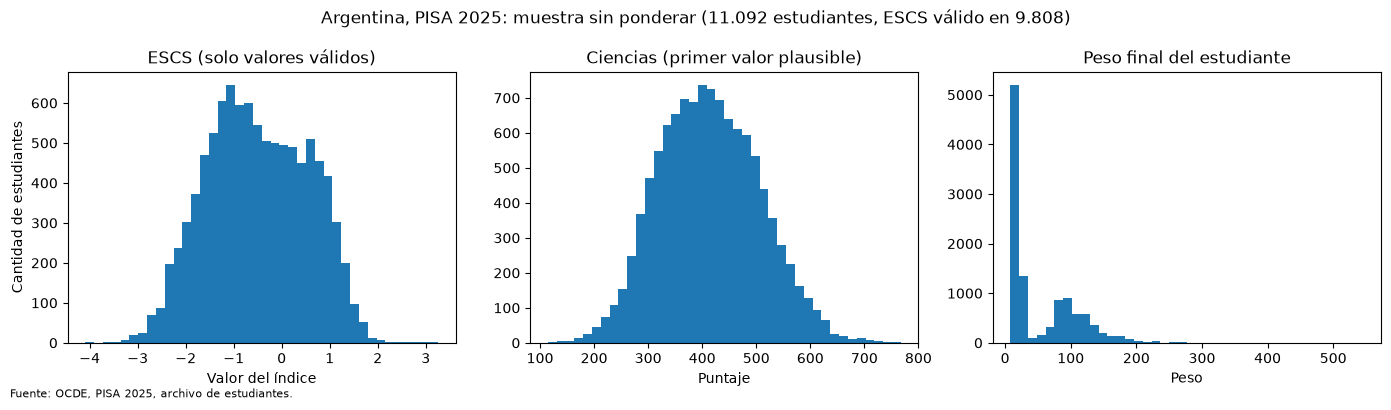

In [9]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))

escs_validos = argentina[argentina["ESCS"] < 95]["ESCS"]
ejes[0].hist(escs_validos, bins=40)
ejes[0].set_title("ESCS (solo valores válidos)")
ejes[0].set_xlabel("Valor del índice")
ejes[0].set_ylabel("Cantidad de estudiantes")

ejes[1].hist(argentina["PV1SCIE"], bins=40)
ejes[1].set_title("Ciencias (primer valor plausible)")
ejes[1].set_xlabel("Puntaje")

ejes[2].hist(argentina["W_FSTUWT"], bins=40)
ejes[2].set_title("Peso final del estudiante")
ejes[2].set_xlabel("Peso")

fig.suptitle("Argentina, PISA 2025: muestra sin ponderar (11.092 estudiantes, ESCS válido en 9.808)")
fig.text(0.01, 0.01, "Fuente: OCDE, PISA 2025, archivo de estudiantes.", fontsize=8)
fig.tight_layout()
fig.savefig(carpeta_figuras / "01_distribuciones_basicas.png", dpi=120)
plt.show()

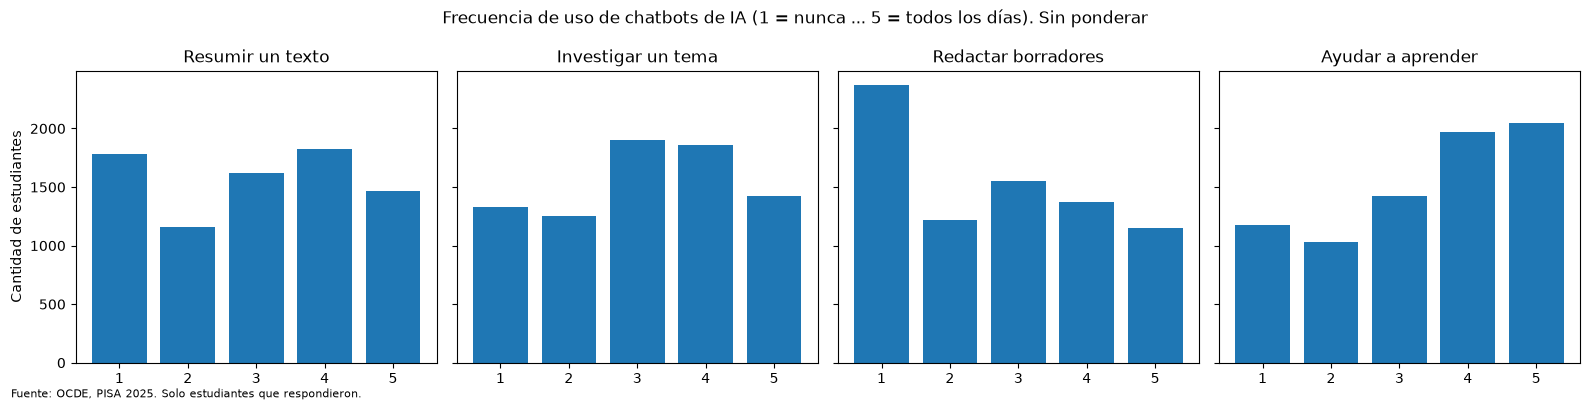

In [10]:
# Respuestas a las cuatro preguntas de IA (solo quienes respondieron 1 a 5)
etiquetas_cortas = {
    1: "Nunca", 2: "1-2 veces al año", 3: "1-2 veces al mes", 4: "1-2 veces por semana", 5: "Todos los días",
}
nombres = {
    "ST438Q01DA": "Resumir un texto",
    "ST438Q02DA": "Investigar un tema",
    "ST438Q03DA": "Redactar borradores",
    "ST438Q04DA": "Ayudar a aprender",
}

fig, ejes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
posicion = 0
for pregunta in preguntas_ia:
    validas = argentina[argentina[pregunta].between(1, 5)][pregunta]
    conteos = validas.value_counts().sort_index()
    ejes[posicion].bar(range(1, 6), conteos.values)
    ejes[posicion].set_title(nombres[pregunta])
    ejes[posicion].set_xticks(range(1, 6))
    posicion = posicion + 1

ejes[0].set_ylabel("Cantidad de estudiantes")
fig.suptitle("Frecuencia de uso de chatbots de IA (1 = nunca ... 5 = todos los días). Sin ponderar")
fig.text(0.01, 0.01, "Fuente: OCDE, PISA 2025. Solo estudiantes que respondieron.", fontsize=8)
fig.tight_layout()
fig.savefig(carpeta_figuras / "01_frecuencia_ia.png", dpi=120)
plt.show()